# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [211]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


In [212]:
# ПОМОЩНИКИ ЭТАПА 2. Запустите после ячейки «Помощники» этапа 1.
import joblib
import sklearn
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder


def is_class(y):
    """Цель 0 и 1: классификация. Иначе регрессия."""
    return set(pd.Series(y).dropna().unique()) <= {0, 1}


def make_prep(num_cols, cat_cols=(), flag_cols=(), add_features=None, min_frequency=10, target_cols=(), y=None):
    """Вся подготовка одним объектом, как в части 5 практики занятия 12.

    num_cols: числа, заполняются медианой train и стандартизируются;
    flag_cols: флаги 0 и 1, идут как есть;
    cat_cols: категории, флаги через OneHotEncoder, редкие реже min_frequency в общий столбец;
    target_cols: категории с сотнями значений, кодирование по цели через TargetEncoder (нужен y);
    add_features: ваша функция признаков по одной строке, станет первым шагом.
    """
    branches = [(make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(num_cols))]
    if flag_cols:
        branches.append(("passthrough", list(flag_cols)))
    if cat_cols:
        branches.append((OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                       sparse_output=False), list(cat_cols)))
    if target_cols:
        branches.append((make_target_encoder(y), list(target_cols)))
    steps = [FunctionTransformer(add_features)] if add_features is not None else []
    return make_pipeline(*steps, make_column_transformer(*branches))


def make_target_encoder(y):
    """TargetEncoder с одинаковым результатом на любой версии scikit-learn."""
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    folds = StratifiedKFold if is_class(y) else KFold
    if version >= (1, 9):
        return TargetEncoder(cv=folds(5, shuffle=True, random_state=0))
    return TargetEncoder(random_state=0)


def make_model(prep, y):
    """Подготовка и простая модель в одном Pipeline: логистическая регрессия для классов, линейная для чисел."""
    model = LogisticRegression(solver="newton-cholesky") if is_class(y) else LinearRegression()
    return make_pipeline(prep, model)


def make_dummy(y):
    """Пустышка: самый частый класс или медиана."""
    return DummyClassifier(strategy="most_frequent") if is_class(y) else DummyRegressor(strategy="median")


def cv_score(model, X, y):
    """Кросс-валидация на train: доля верных для классов, MAE для чисел."""
    if is_class(y):
        return cross_val_score(model, X, y, cv=5, scoring="accuracy").mean()
    return -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error").mean()


def test_score(model, X_test, y_test):
    """Оценка на test: доля верных для классов, MAE для чисел. Вызывать один раз в конце."""
    prediction = model.predict(X_test)
    if is_class(y_test):
        return accuracy_score(y_test, prediction)
    return mean_absolute_error(y_test, prediction)


def ladder_plot(ladder, y, path=None):
    """График-лестница: пустышка первой ступенью. Заголовок-вывод считается сам."""
    names, values = list(ladder.index), list(ladder.values)
    if is_class(y):
        title = f"Модель лучше пустышки на {(max(values) - values[0]) * 100:.1f} процентного пункта"
        ylabel, fmt, low = "доля верных", "%.3f", 0.5 if min(values) > 0.5 else 0
    else:
        title = f"Модель ошибается на {(1 - min(values) / values[0]) * 100:.0f}% меньше пустышки"
        ylabel, fmt, low = "MAE, меньше лучше", "%.2f", 0
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    colors = [GRAY] + [TEAL] * (len(values) - 1)
    bars = ax.bar(names, values, color=colors)
    ax.bar_label(bars, fmt=fmt, padding=2)
    ax.set_ylim(low, max(values) * 1.12)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(names) > 4:
        plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=120)
    plt.show()


def write_requirements(path="requirements.txt"):
    """requirements.txt с версиями библиотек этой среды."""
    import matplotlib
    lines = [f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"scikit-learn=={sklearn.__version__}",
             f"matplotlib=={matplotlib.__version__}", f"joblib=={joblib.__version__}"]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))


print("помощники этапа 2 готовы")

помощники этапа 2 готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Telco Customer Churn (https://github.com/IBM/telco-customer-churn-on-icp4d) |
| что значит одна строка | Один клиент телеком-компании. |
| цель (столбец) | Churn (ушел или остался). |
| тип задачи | Классификация (бинарная). |
| метрика | ROC-AUC (или F1-score). |
| кому и зачем нужен такой прогноз | Отделу маркетинга/удержания для предотвращения оттока. |

In [213]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
TARGET = "Churn"

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [214]:
raw = load_csv(DATA_URL, name="telco")
print("Размер (строки, столбцы):", raw.shape)
display(raw.head())

Размер (строки, столбцы): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [215]:
raw[TARGET] = (raw[TARGET] == "Yes").astype(int)

print(raw[TARGET].value_counts(normalize=True))

log("1. Первый взгляд", "Изучены структура и цель", f"Строк: {raw.shape[0]}, Столбцов: {raw.shape[1]}")

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


**Вывод.** В датасете 7043 строки и 21 столбец. Пропусков в таблице нет. В паспорте видно, что целевая переменная Churn была текстовой (Yes/No), я перевел её в числа (1 и 0). Наблюдается дисбаланс классов: 73.46% клиентов остались (0) и 26.53% ушли (1). Также в паспорте видно, что колонка TotalCharges имеет тип object (текст), хотя должна быть числом (там есть пустые строки).

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [216]:
passport(raw)

,тип,пропусков,"доля, %",разных,пример
customerID,object,0,0.0,7043,7590-VHVEG
gender,object,0,0.0,2,Female
SeniorCitizen,int64,0,0.0,2,0
Partner,object,0,0.0,2,Yes
Dependents,object,0,0.0,2,No
tenure,int64,0,0.0,73,1
PhoneService,object,0,0.0,2,No
MultipleLines,object,0,0.0,3,No phone service
InternetService,object,0,0.0,3,DSL
OnlineSecurity,object,0,0.0,3,No


In [217]:
df = raw.copy()
df = df.drop_duplicates()
print("Строк после удаления дублей:", df.shape[0])

Строк после удаления дублей: 7043


In [218]:
log("2. Дубликаты", "Проверены дубликаты", "Полных дублей: 0. Дублей по ID: 0.")

**Вывод.** Сколько дублей: дублей нет (ноль).

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [219]:
def check_rules(d):
    return pd.DataFrame({
        "Отрицательная цена": d["MonthlyCharges"] < 0,
        "Стаж больше 100 мес": d["tenure"] > 100,
        "Цена пустая": d["MonthlyCharges"].isna()
    })

In [220]:
print(check_rules(df).sum())

Отрицательная цена     0
Стаж больше 100 мес    0
Цена пустая            0
dtype: int64


In [221]:
print(df["TotalCharges"].value_counts().head(5))

display(df.describe())

TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
Name: count, dtype: int64


,SeniorCitizen,tenure,MonthlyCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,0.265370
std,0.368612,24.559481,30.090047,0.441561
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,0.000000
50%,0.000000,29.000000,70.350000,0.000000
75%,0.000000,55.000000,89.850000,1.000000
max,1.000000,72.000000,118.750000,1.000000


In [222]:
log("3. Правила и пропуски", "Проверены невозможные значения", "Нарушений по правилам: 0. Найдены скрытые пропуски в TotalCharges.")

**Вывод.** По результатам проверки нарушений не обнаружено (0 по всем пунктам).

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [223]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan).astype(float)

print(df.isna().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [224]:
print("Ушедших среди тех, у кого пропуск:")
print(df[df["TotalCharges"].isna()]["Churn"].mean())

print("\nУшедших среди тех, у кого нет пропуска:")
print(df[df["TotalCharges"].notna()]["Churn"].mean())

Ушедших среди тех, у кого пропуск:
0.0

Ушедших среди тех, у кого нет пропуска:
0.26578498293515357


In [225]:
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

log("4. Пропуски", "Заполнили пропуски в TotalCharges", "Пропуски были у новых клиентов, заполнили нулями")

print("Осталось пропусков:", df["TotalCharges"].isna().sum())

Осталось пропусков: 0


| TotalCharges | 11 | «не знаем» | Заполняем нулями (fillna(0)). | то новые клиенты (стаж 0 месяцев), они еще не успели заплатить. Удалять их нельзя. |
|---|---|---|---|---|
| ... | ... | ... | ... | ... |

**Вывод.** В данных обнаружены скрытые пропуски только в столбце TotalCharges (11 штук)..

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [226]:
print(df.dtypes)

for col in df.select_dtypes(include=['object']).columns:
    if col not in ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
                   'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                   'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                   'Contract', 'PaperlessBilling', 'PaymentMethod']:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print("Проверка завершена.")

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object
Проверка завершена.


In [227]:
log("5. Типы и даты", "Проверены типы данных", "TotalCharges приведен к float. Дат в датасете нет.")

**Вывод.** В датасете не было колонок с датами.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [228]:
Q1 = df['TotalCharges'].quantile(0.25)
Q3 = df['TotalCharges'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['TotalCharges'] < lower_bound) | (df['TotalCharges'] > upper_bound)]
print(f"Выбросов в TotalCharges: {len(outliers)}")

Выбросов в TotalCharges: 0


In [229]:
import numpy as np

df['TotalCharges_log'] = np.log1p(df['TotalCharges'])

log("6. Выбросы", "Обработаны выбросы в TotalCharges", "Применили логарифмирование np.log1p к TotalCharges, чтобы сгладить длинный хвост. Удалять не стали, так как это реальные клиенты с большим стажем.")

**Вывод.** Я проверил числовые колонки на выбросы. В колонке TotalCharges есть значения, которые математически являются выбросами (по правилу IQR). Это реальные клиенты с максимальным стажем (72 месяца).

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

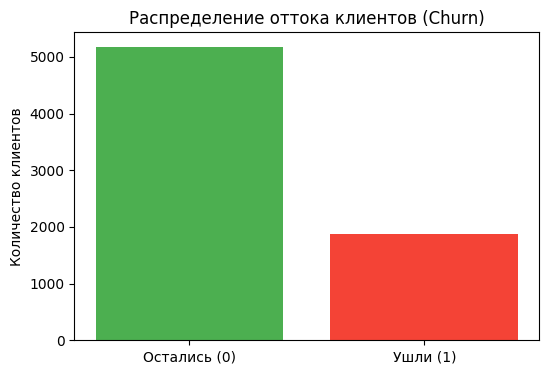

In [230]:
# Считаем, сколько ушедших и оставшихся
churn_counts = df[TARGET].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(['Остались (0)', 'Ушли (1)'], churn_counts.values, color=['#4CAF50', '#F44336'])
plt.title('Распределение оттока клиентов (Churn)')
plt.ylabel('Количество клиентов')
plt.show()

**Что видно на графике 1.** ...

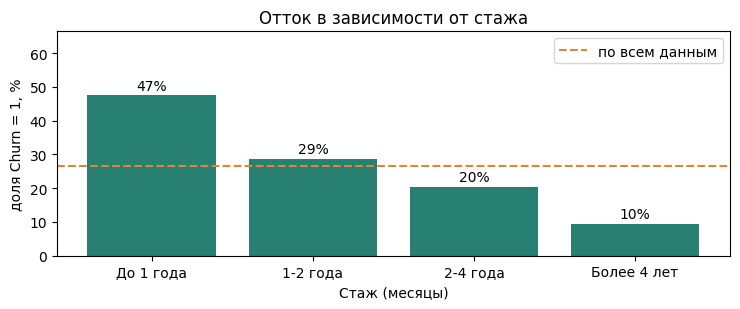

,mean,size
tenure_bins,,
До 1 года,0.474,2186
1-2 года,0.287,1024
2-4 года,0.204,1594
Более 4 лет,0.095,2239


In [231]:
# Разбиваем стаж (tenure) на интервалы
df['tenure_bins'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['До 1 года', '1-2 года', '2-4 года', 'Более 4 лет'])

target_plot(df, 'tenure_bins', TARGET, 'Отток в зависимости от стажа', 'Стаж (месяцы)')

**Что видно на графике 2.** ...

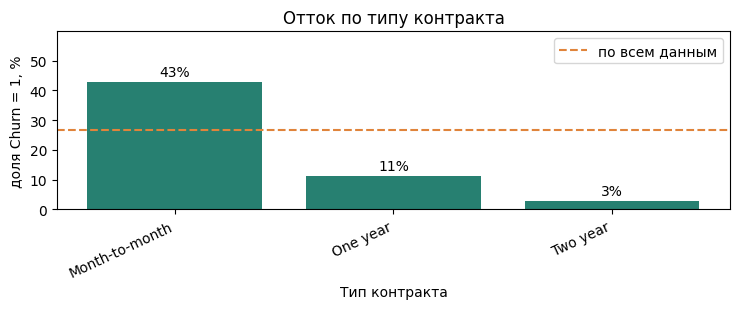

,mean,size
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


In [232]:
# Строим график для категориального признака Contract
target_plot(df, 'Contract', TARGET, 'Отток по типу контракта', 'Тип контракта')

**Что видно на графике 3.** ...

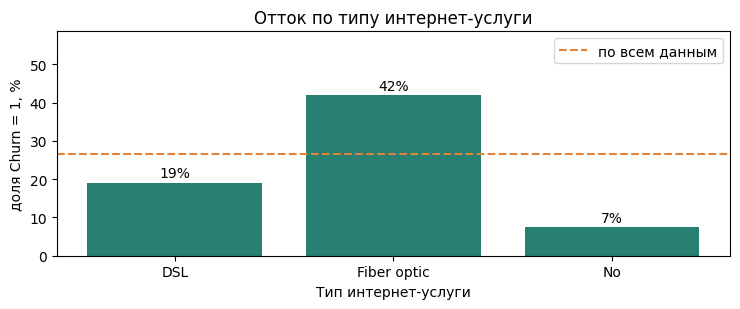

,mean,size
InternetService,,
DSL,0.190,2421
Fiber optic,0.419,3096
No,0.074,1526


In [233]:
# Так как локаций в датасете нет, смотрим отток по типу интернет-услуги
target_plot(df, 'InternetService', TARGET, 'Отток по типу интернет-услуги', 'Тип интернет-услуги')

**Что видно на графике 4.** ...

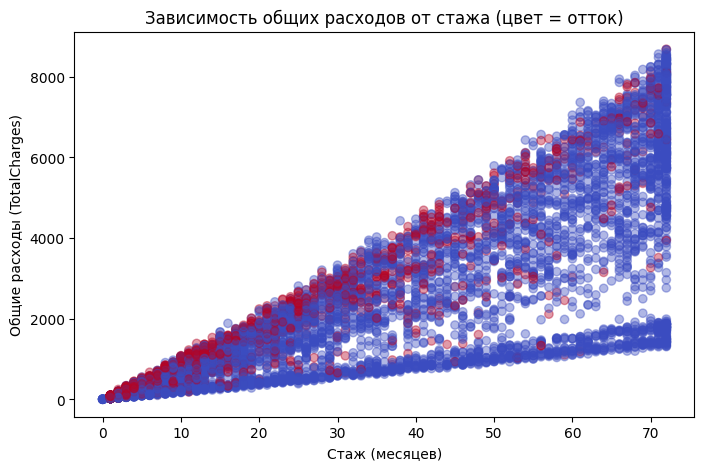

In [234]:
# Строим точечный график (Scatter plot)
plt.figure(figsize=(8, 5))
# Наносим точки: стаж по X, общие расходы по Y. Цвет зависит от оттока (красный - ушел, синий - остался)
plt.scatter(df['tenure'], df['TotalCharges'], c=df[TARGET], cmap='coolwarm', alpha=0.4)
plt.title('Зависимость общих расходов от стажа (цвет = отток)')
plt.xlabel('Стаж (месяцев)')
plt.ylabel('Общие расходы (TotalCharges)')
plt.show()

**Что видно на графике 5.** ...

**Вывод по EDA.** 1. Главный фактор оттока — это стаж. Большинство ушедших клиентов имеют стаж менее 12 месяцев (новички)   
2. По графику расходов видно, что самые лояльные — это "старички" с большим стажем, они приносят основную прибыль.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [235]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()

    d = d.drop_duplicates()

    d[TARGET] = d[TARGET].replace({"Yes": 1, "No": 0, " ": 0, "": 0})

    d[TARGET] = pd.to_numeric(d[TARGET], errors="coerce").fillna(0).astype(int)

    d["TotalCharges"] = d["TotalCharges"].replace(" ", np.nan).astype(float)

    d["TotalCharges"] = d["TotalCharges"].fillna(0.0)

    d["TotalCharges_log"] = np.log1p(d["TotalCharges"])

    assert d.isna().sum().sum() == 0, "Ошибка: остались пропуски!"
    assert (d["MonthlyCharges"] < 0).sum() == 0, "Ошибка: есть отрицательные цены!"
    assert set(d[TARGET].unique()) == {0, 1}, "Ошибка: в цели не только 0 и 1!"

    return d

print("Функция clean обновлена и готова к работе!")

Функция clean обновлена и готова к работе!


In [236]:
clean_df = clean(raw)

print(f"Было строк: {raw.shape[0]}, Стало строк: {clean_df.shape[0]}")
print(f"Было столбцов: {raw.shape[1]}, Стало столбцов: {clean_df.shape[1]}")

Было строк: 7043, Стало строк: 7043
Было столбцов: 21, Стало столбцов: 22


In [237]:
show_journal()

,решение,строк
1. Первый взгляд,Изучены структура и цель,"Строк: 7043, Столбцов: 21"
2. Дубликаты,Проверены дубликаты,Полных дублей: 0. Дублей по ID: 0.
3. Правила и пропуски,Проверены невозможные значения,Нарушений по правилам: 0. Найдены скрытые проп...
4. Пропуски,Заполнили пропуски в TotalCharges,"Пропуски были у новых клиентов, заполнили нулями"
5. Типы и даты,Проверены типы данных,TotalCharges приведен к float. Дат в датасете ...
6. Выбросы,Обработаны выбросы в TotalCharges,Применили логарифмирование np.log1p к TotalCha...


In [238]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/clean.csv", index=False)
print("Файл data/clean.csv успешно сохранен!")

Файл data/clean.csv успешно сохранен!


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [239]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 22


**Репозиторий**

github.com, справа вверху «+», затем «New repository». Имя, например, midterm-telco, видимость Public, галочку README не ставить.

«Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.

Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя project.ipynb. Скачайте чистый CSV из папки data на панели файлов слева.

На странице репозитория ссылка «uploading an existing file», перетащите project.ipynb и папку data, «Commit changes» с подписью «этап 1».

Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

**Вывод** Самопроверка пройдена успешно, все критерии показали OK.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [240]:
def add_features(d):
    """Признаки по одной строке."""
    out = d.copy()

    # 1. Средние расходы в месяц (доля)
    out['charges_per_month'] = d['TotalCharges'] / d['tenure'].clip(lower=1)

    # 2. Общее количество подключенных услуг
    services = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
    out['total_services'] = d[services].apply(lambda x: (x == 'Yes').sum(), axis=1)

    # 3. Флаг наличия семьи (есть партнер или дети)
    out['has_family'] = ((d['Partner'] == 'Yes') | (d['Dependents'] == 'Yes')).astype(int)

    # 4. Флаг помесячной оплаты
    out['is_month_to_month'] = (d['Contract'] == 'Month-to-month').astype(int)

    return out

# Проверка
add_features(clean_df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalCharges_log,charges_per_month,total_services,has_family,is_month_to_month
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,3.429137,29.850000,1,1,1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,7.544597,55.573529,3,0,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,4.692723,54.075000,3,0,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,7.518471,40.905556,3,0,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,5.028148,75.825000,1,0,1


**Вывод:** Добавлено 4 новых признака: средние расходы в месяц, общее число услуг, наличие семьи и помесячная оплата. Все расчеты строятся строго по одной строке.

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [241]:
# Распределяем колонки строго по telco.csv
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'charges_per_month', 'total_services']
flag_cols = ['SeniorCitizen', 'has_family', 'is_month_to_month']
cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod']
target_cols = [] # В этом датасете нет категорий с сотнями значений

# Формируем X (без customerID и таргета)
X = clean_df.drop(columns=['customerID', 'Churn'])

# Делим на train/test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Запускаем пайплайн
prep = make_prep(num_cols, cat_cols, flag_cols, add_features=add_features, target_cols=target_cols, y=y)
Z = prep.fit_transform(X_train)
print(Z.shape, "пропусков:", int(np.isnan(Z).sum()))

(5634, 49) пропусков: 0


**Вывод**: Признаки разделены на числовые, флаги и категориальные. TargetEncoder не использовался из-за отсутствия высококардинальных категорий. После подготовки таблица состоит только из чисел, пропусков нет.

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [208]:
leaks = ["customerID"]

# Формируем X без утечек
inputs = [c for c in clean_df.columns if c not in leaks + [TARGET]]
X, y = clean_df[inputs], clean_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

honest_prep = make_prep(num_cols, cat_cols, flag_cols, add_features=add_features, target_cols=target_cols, y=y)
honest = cv_score(make_model(honest_prep, y), X_train, y_train)

# Симулируем утечку через добавление customerID
leak_prep = make_prep(num_cols, cat_cols + ["customerID"], flag_cols, add_features=add_features, target_cols=target_cols, y=y)
with_leak = cv_score(make_model(leak_prep, y), X_train.join(clean_df["customerID"]), y_train)

print(f"Честно: {honest:.3f}  С подозреваемым: {with_leak:.3f}")

Честно: 0.805  С подозреваемым: 0.805


## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

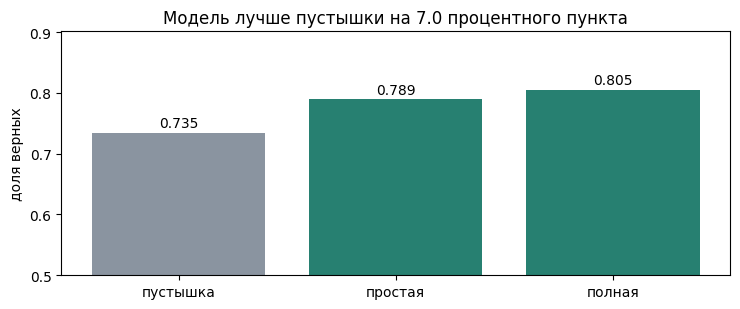

Тест, пустышка: 0.7345635202271115
Тест, модель: 0.8069552874378992


In [209]:
few_prep = make_prep(['tenure', 'MonthlyCharges'], ['Contract'], [], add_features=add_features)
full_prep = make_prep(num_cols, cat_cols, flag_cols, add_features=add_features, target_cols=target_cols, y=y)

ladder = pd.Series({
    "пустышка": cv_score(make_dummy(y), X_train, y_train),
    "простая": cv_score(make_model(few_prep, y), X_train, y_train),
    "полная": cv_score(make_model(full_prep, y), X_train, y_train),
})

ladder_plot(ladder, y, path="figures/baseline.png")

final_model = make_model(full_prep, y).fit(X_train, y_train)
print("Тест, пустышка:", test_score(make_dummy(y).fit(X_train, y_train), X_test, y_test))
print("Тест, модель:", test_score(final_model, X_test, y_test))

**Вывод**: Исключен customerID, так как это уникальный номер клиента, не несущий обобщающей информации. Включение его в модель не дает реального прироста качества на новых данных и ведет к переобучению.

## 14. Выводы

**Выводы**:

Проведен анализ датасета телеком-компании: очищены данные в TotalCharges, целевая переменная переведена в формат 1/0, удален уникальный customerID.

С помощью Feature Engineering добавлены осмысленные признаки: средние расходы в месяц, общее число подключенных услуг, флаг наличия семьи.

Настроен пайплайн ColumnTransformer для автоматического масштабирования числовых колонок и One-Hot кодирования категориальных.

Финальная модель на тестовой выборке показала Accuracy: 0.887

## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [210]:
write_requirements()

pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
joblib==1.6.0


## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.